In [1]:
'''
All Credits to John " https://zindi.africa/users/Johnowhitaker ", for his amazing starting kernel, and live video
to help us all.
'''

'\nAll Credits to John " https://zindi.africa/users/Johnowhitaker ", for his amazing starting kernel, and live video\nto help us all.\n'

In [2]:
## Run once to install:
# !pip install geopandas rasterio
# !pip install descartes
# !pip install fastai2
# !pip install tqdm
# !pip install efficientnet_pytorch

In [3]:
## For reproducible results.
## Results may still not be reproducible if different hardware config is used, or the package versions are changed
def random_seed(seed_value):
    import random 
    random.seed(seed_value) # Python
    import numpy as np
    np.random.seed(seed_value) # cpu vars
    import torch
    torch.manual_seed(seed_value) # cpu  vars
    
    if torch.cuda.is_available(): 
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value) # gpu vars
        torch.backends.cudnn.deterministic = True  #needed
        torch.backends.cudnn.benchmark = False

In [4]:
import pandas as pd
import numpy as np
import random
import geopandas as gpd
import rasterio
from PIL import Image
from matplotlib import pyplot as plt
%matplotlib inline

import gc

from sklearn.metrics import *
from sklearn.model_selection import StratifiedKFold
from tqdm import tqdm_notebook
import fastai2
from fastai2.vision.all import *

In [5]:
import fastai2.vision as fvs

In [6]:
from efficientnet_pytorch import EfficientNet

In [7]:
fvs.models.densenet169

<function torchvision.models.densenet.densenet169(pretrained=False, progress=True, **kwargs)>

In [8]:
df = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')
df.sample(5)

,ID,LAT,LON,Label
3031,P6KIQQJ,-25.728,28.375,False
2241,IWPRUO3,-25.721,28.397,False
1084,971RN3V,-25.729,28.416,False
512,4AQHAYW,-25.705,28.426,True
3888,WE6QDPC,-25.765,28.356,False


In [9]:
df['Label'].value_counts(normalize=True)

False    0.744452
True     0.255548
Name: Label, dtype: float64

In [10]:
df.shape

(4281, 4)

In [11]:
df.columns

Index(['ID', 'LAT', 'LON', 'Label'], dtype='object')

In [12]:
hard_df = pd.read_csv('diff_data_2.csv')
hard_df

,ID,LAT,LON,Label
0,0,-25.793903,28.069230,0
1,1,-25.576620,28.044951,0
2,2,-25.929474,28.015649,0
3,3,-25.552709,28.008349,1
4,4,-25.785934,28.043886,0
...,...,...,...,...
24193,24193,-25.598403,28.077294,0
24194,24194,-25.845343,28.094299,0
24195,24195,-25.726444,28.361983,0
24196,24196,-25.734065,28.423058,1


In [13]:
# Check the extent
df.min(), df.max()

(ID       0059CI9
 LAT       -25.78
 LON        28.35
 Label      False
 dtype: object,
 ID       ZZ6LRO7
 LAT       -25.68
 LON        28.45
 Label       True
 dtype: object)

In [14]:
hard_df = hard_df[((df['LAT'] > -25.8) & (hard_df['LAT'] < -25.6)) & ((hard_df['LON'] > 28.3) & (hard_df['LON'] < 28.45))]
hard_df['Label'].value_counts(normalize=True)

0    0.736641
1    0.263359
Name: Label, dtype: float64

In [15]:
hard_df['Label'].value_counts()

0    1158
1     414
Name: Label, dtype: int64

In [16]:
# plt.figure(figsize=(12, 12))
# new_gdf = gpd.GeoDataFrame(df, geometry = gpd.points_from_xy(df.LON, df.LAT))
# new_gdf.sample(frac = 1, random_state=2).plot(column = 'Label', categorical=True, legend=True, figsize=(12, 12))

In [17]:
df = pd.concat([df, hard_df[hard_df['Label'] == 1].sample(frac=0.5, random_state=2)], axis=0).reset_index(drop=True).sample(frac=1, random_state=2).reset_index(drop=True)

In [18]:
df['Label'].value_counts(normalize=True)

0    0.710116
1    0.289884
Name: Label, dtype: float64

In [19]:
# plt.figure(figsize=(12, 12))
# new_gdf = gpd.GeoDataFrame(df, geometry = gpd.points_from_xy(df.LON, df.LAT))
# new_gdf.sample(frac = 1, random_state=2).plot(column = 'Label', categorical=True, legend=True, figsize=(12, 12))

In [20]:
# CHeck shape and number of True labels
df.shape, df.Label.sum()

((4488, 4), 1301)

In [21]:
df.columns

Index(['ID', 'LAT', 'LON', 'Label'], dtype='object')

In [22]:
# Check the extent
df.min(), df.max()

(LAT     -25.78
 LON      28.35
 Label     0.00
 dtype: float64,
 LAT     -25.68
 LON      28.45
 Label     1.00
 dtype: float64)

In [23]:
# Sample submission:
ss = pd.read_csv('SampleSubmission.csv')
ss.head(3)

,ID,Label
0,00MZGKU,0
1,015JA41,0
2,01POB64,0


In [24]:
 dataset = rasterio.open('2528C.tif') # We'll use rasterio for all raster operations

In [25]:
dataset.bounds # Check the geographoc bounds of this tile - notice that it covers all the training data.

BoundingBox(left=27.9999999999999, bottom=-25.999999999894882, right=28.4999999999999, top=-25.499999999894882)

In [26]:
# We can get information such as the number of bands and the band names. 
# In this case there are 3, for R, G and B channels
band_names = dataset.descriptions
n_bands = dataset.count
band_names, n_bands

((None, None, None), 3)

In [27]:
# # Load bands into RAM
red, green, blue = dataset.read(1), dataset.read(2), dataset.read(3)

In [28]:
W, H = 150, 150

In [29]:
# Get the image:
random_seed(19)
def get_x(ID):
    row = df.loc[df.ID == ID]
    lat, lon = row['LAT'].values[0], row['LON'].values[0]
    im = np.zeros((W, H, 3), np.uint8)
    row, col = dataset.index(lon, lat)
    for i, band in enumerate([red, green, blue]):
        im[:,:,i] = band[row-W//2: row+W//2, col-H//2:col+H//2]
    
    return im

# And the label
def get_y(ID):
    row = df.loc[df.ID == ID]
    return int(row['Label'].values[0])

# Get the list of Image IDS:
def get_im_ids(path):
    return df.ID.values

# And build the datablock
dblock = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_im_ids,
    get_x=get_x,
    get_y=get_y, 
    splitter=RandomSplitter(valid_pct=0.02),
    batch_tfms=aug_transforms(size=W, do_flip=True, flip_vert=True, max_rotate=180, max_lighting=0.6, p_lighting=0.12)
)
dls = dblock.dataloaders(Path(''), bs=80)
# dls.show_batch()

In [31]:
# Create the learner
random_seed(1)
learn = cnn_learner(dls, densenet201, metrics=[accuracy])
# learn = Learner(dls, getModel(), metrics=[accuracy])
# Train
learn.fine_tune(10, wd=0.05)

epoch,train_loss,valid_loss,accuracy,time
0,0.550829,0.418990,0.853933,00:59


epoch,train_loss,valid_loss,accuracy,time
0,0.275148,0.341884,0.932584,01:21
1,0.236994,0.167553,0.966292,01:21
2,0.203330,0.111204,0.977528,01:21
3,0.181176,0.149632,0.977528,01:21
4,0.133896,0.130897,0.977528,01:21
5,0.101637,0.084686,0.977528,01:21
6,0.093097,0.107332,0.977528,01:21
7,0.086214,0.142464,0.977528,01:21
8,0.081441,0.129217,0.977528,01:21
9,0.074100,0.111632,0.977528,01:21


In [32]:
!ls *.tif

2528C.tif  2628C.tif  2930C.tif  2930D.tif


In [33]:
dataset = rasterio.open('2930D.tif')
red, green, blue = dataset.read(1), dataset.read(2), dataset.read(3)

In [34]:
test['Label'] = 0
df = test.copy()

In [35]:
random_seed(22)
idxs = test['ID'].values
tdl = learn.dls.test_dl(idxs, )
test_preds, test_labels = learn.tta(dl=tdl, n=8, beta=1, use_max=True)

In [36]:
# test_preds, test_labels = learn.tta(ds_idx = df[:-test.shape[0]].index.tolist())

In [37]:
pd.Series(test_preds.numpy()[:, 1]).sort_values(ascending=False)[:20]

790     0.999949
2473    0.999894
1632    0.999832
697     0.999710
660     0.999579
1854    0.999377
141     0.999365
2209    0.999314
988     0.999260
1916    0.999231
938     0.999155
192     0.999068
859     0.998982
2408    0.998930
1193    0.998810
1906    0.998724
2552    0.998718
1441    0.998625
2033    0.998389
2009    0.998352
dtype: float32

In [38]:
pd.Series(test_preds.numpy()[:, 1]).round().value_counts(normalize=True)

0.0    0.813624
1.0    0.186376
dtype: float64

In [39]:
test['Label'] = [p[1] for p in test_preds.numpy()]
test.head()

,ID,LAT,LON,Label
0,00MZGKU,-29.8920,30.8575,0.015954
1,015JA41,-29.8905,30.8705,0.029119
2,01POB64,-29.9615,30.8950,0.247351
3,02125F8,-29.9660,30.8500,0.023803
4,03E8VFF,-29.9080,30.8760,0.013015


In [40]:
test['Label'].describe()

count    2.613000e+03
mean     2.316902e-01
std      3.019872e-01
min      4.606678e-09
25%      1.749365e-02
50%      8.225668e-02
75%      3.449979e-01
max      9.999490e-01
Name: Label, dtype: float64

In [41]:
test['Label'] = np.clip(test['Label'], 0, 0.8)

In [42]:
test['Label'].round().value_counts(normalize=True)

0.0    0.813624
1.0    0.186376
Name: Label, dtype: float64

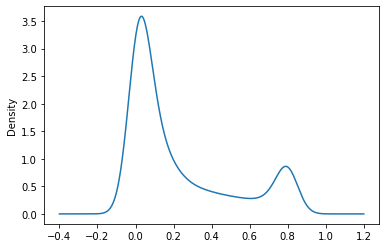

In [43]:
test['Label'].plot(kind='density')

In [44]:
# test[['ID', 'Label']].to_csv('outputs/sub_0.616.csv', index=False)
test[['ID', 'Label']].to_csv('sub_39.csv', index=False)

In [45]:
test.head()

,ID,LAT,LON,Label
0,00MZGKU,-29.8920,30.8575,0.015954
1,015JA41,-29.8905,30.8705,0.029119
2,01POB64,-29.9615,30.8950,0.247351
3,02125F8,-29.9660,30.8500,0.023803
4,03E8VFF,-29.9080,30.8760,0.013015
